In [32]:
#All the imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import os
from concurrent.futures import ProcessPoolExecutor

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_spectra_at_time
from shared.loading import grid_spacing
from shared.paths import BRMS, results_dir, run_dir
from shared.plotting import add_slope_guide, save_figure, use_style
use_style()
RESULTS = results_dir("quality_checks", "AvgSpectrum")

In [33]:
def spectra_at(output_time):
    """(k, B spectrum, J spectrum, n spectrum) at one output time of RUN."""
    print(output_time)
    return compute_spectra_at_time(RUN, output_time, DX, DY)

In [34]:
# ---- run, grid and times ----
RUN = run_dir(beta_p=1, beta_e=1, brms=BRMS)
DX, DY = grid_spacing(RUN)
AVERAGE_TIMES = [270]                # output times averaged together (a single time: no averaging)
N_WORKERS = os.cpu_count()

# ---- plot ----
K_RANGE_SHOWN = (5e-2, 30)
POWER_RANGE_SHOWN = (1e-6, 1)
# slope guides: (slope, k_min, k_max, label, spectrum it is drawn along)
SLOPE_GUIDES = [(-3, 2.95, 19.6, r'$k_\perp^{-3}$', "B"), (-1, 4.9, 19.6, r'$k_\perp^{-1}$', "J"),
                (-5/3, 0.37, 2.45, r'$k_\perp^{-5/3}$', "B"), (-2.8, 4.9, 19.6, r'$k_\perp^{-2.8}$', "n")]

if len(AVERAGE_TIMES) == 1:
    TIME_LABEL, LEGEND_NOTE = f"t{AVERAGE_TIMES[0]}", f"t = {AVERAGE_TIMES[0]}"
else:
    TIME_LABEL = f"t{AVERAGE_TIMES[0]}-{AVERAGE_TIMES[-1]}_average"
    LEGEND_NOTE = f"average of {len(AVERAGE_TIMES)} outputs"

In [35]:
AVERAGE_TIMES

array([270])

In [36]:
with ProcessPoolExecutor(max_workers=min(N_WORKERS, len(AVERAGE_TIMES))) as executor:
    results = list(executor.map(spectra_at, AVERAGE_TIMES))

270


In [37]:
k_perp = results[0][0]  # same for all

spectra_B = np.array([result[1] for result in results])
spectra_J = np.array([result[2] for result in results])
spectra_D = np.array([result[3] for result in results])

spectra_B_avg = np.mean(spectra_B, axis=0)
spectra_J_avg = np.mean(spectra_J, axis=0)
spectra_D_avg = np.mean(spectra_D, axis=0)

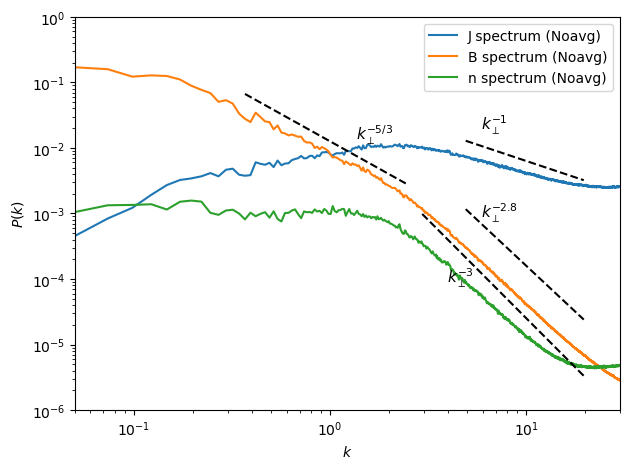

In [40]:
fig, ax = plt.subplots()
ax.loglog(k_perp, spectra_J_avg, label=f"J spectrum ({LEGEND_NOTE})")
ax.loglog(k_perp, spectra_B_avg, label=f"B spectrum ({LEGEND_NOTE})")
ax.loglog(k_perp, spectra_D_avg, label=f"n spectrum ({LEGEND_NOTE})")

spectra_by_name = {"B": spectra_B_avg, "J": spectra_J_avg, "n": spectra_D_avg}
for slope, k_min, k_max, label, name in SLOPE_GUIDES:
    add_slope_guide(ax, k_perp, spectra_by_name[name], slope, k_min, k_max, label=label)

ax.set_xlabel(r"$k$")
ax.set_ylabel(r"$P(k)$")
ax.set_xlim(*K_RANGE_SHOWN)
ax.set_ylim(*POWER_RANGE_SHOWN)
ax.legend()
save_figure(fig, RESULTS, f"spectra_J_B_n_{TIME_LABEL}")
plt.show()

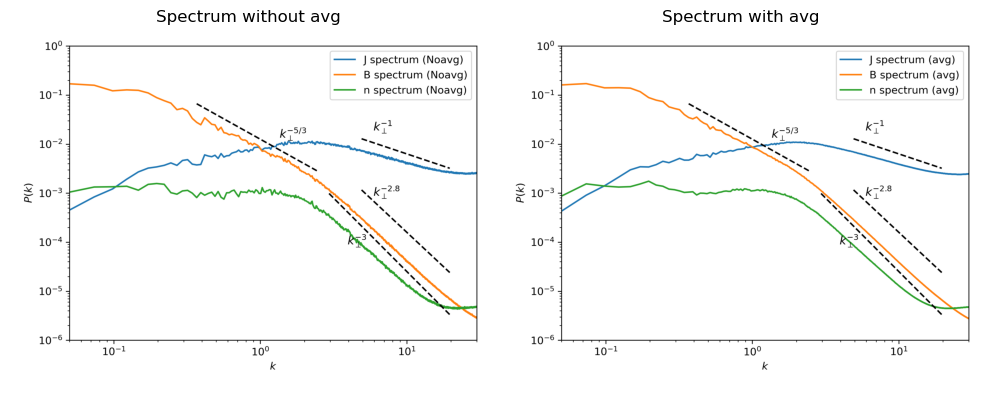

In [39]:
# The figure for one time next to an averaged one. Make each with the cells above (set AVERAGE_TIMES),
# then name them here.
from PIL import Image

SINGLE_TIME_FIGURE = "spectra_J_B_n_t270"
AVERAGED_FIGURE = None               # e.g. "spectra_J_B_n_t200-300_average"

compared = {"Spectrum without avg": SINGLE_TIME_FIGURE, "Spectrum with avg": AVERAGED_FIGURE}
missing = [name for name in compared.values() if name is None or not (RESULTS / f"{name}.png").exists()]
if missing:
    print("make (and name) these figures first:", missing)
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, (title, name) in zip(axes, compared.items()):
        ax.imshow(Image.open(RESULTS / f"{name}.png"))
        ax.set_title(title)
        ax.axis("off")
    save_figure(fig, RESULTS, "spectra_single_time_vs_average")
    plt.show()